In [1]:
from anemone.system import *
from anemone.forwards import Forward

In [2]:
from anemone.forwards import *

class Forward2(BaseForward):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance)
        self.t2t = None

    def forward(self):
        
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)*self.lmb / c.fourpi
                intg = rte(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                return intg.squeeze()
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
            else:
                Hr = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega.squeeze())
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier(frq_integrand, device=self.device, tolerance=self.tolerance)
            
            def t2t_func(t_in):
                if self.t_gatewidth is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
            self.bstep = self.cbft(self.times)
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze())*self.omega1.squeeze())
        self.dpred = Ht.real
        return self.dpred

In [3]:
from anemone.forwards import OnTimeForward

In [4]:
tx = Loop.square(3., z=1.)
rx = Receiver(x = 10., z=0.5)
times = torch.logspace(-8, -3, 51, dtype=torch.double)

DEFAULT_WAVE_T = torch.tensor([
    -2.00e-04, -1.75e-04, -1.50e-04, -1.25e-04, -1.00e-04, -7.50e-05,
    -5.00e-05, -2.50e-05,  0.00e+00,  1.00e-06,  2.00e-06,  3.00e-06,
     4.00e-06,  4.10e-06,  4.20e-06,  4.30e-06,  4.40e-06,  4.50e-06,
])
DEFAULT_WAVE_A = torch.tensor([0.00000, 0.25582, 0.45505, 0.61022, 0.73106, 0.82517,
    0.89846, 0.95555, 1.00000, 0.21544, 0.046416, 0.01000,
    0.0021544, 0.0018478, 0.0015849, 0.0013594, 0.0011659, 0.00000,
])
wv = Waveform(DEFAULT_WAVE_T, DEFAULT_WAVE_A)

rho = torch.ones(3)*40.
thick = torch.ones(2)*20

rxfilt = ButterworthFilter(800e3)
fwr0 = OnTimeForward(tx, rx, times, waveform=wv)
fwr800 = OnTimeForward(tx, rx, times, waveform=wv)

dbdt = fwr0(rho, thick)
dbdt800 = fwr800(rho, thick)

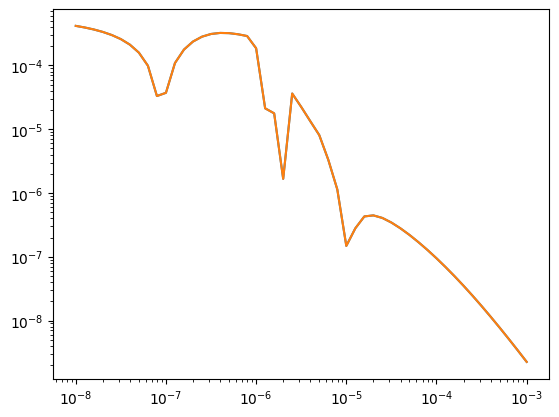

In [5]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(times.numpy(), np.abs(dbdt.numpy()))
plt.loglog(times.numpy(), np.abs(dbdt800.numpy()))
# plt.loglog(times.numpy(), -dbdt.numpy(), '--')
# plt.xlim(1e-6, 1e-5)
# plt.ylim(1e-5, 3e-4)

ValueError: x and y must have same first dimension, but have shapes (51,) and (133,)

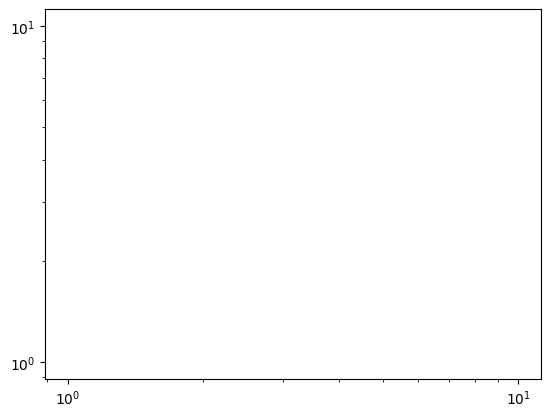

In [6]:
plt.figure()
plt.loglog(times.numpy(),  fwr0.bstep.numpy())
plt.loglog(times.numpy(), -fwr0.bstep.numpy())